In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load

In [34]:
# Hizmet türü verisi
service_df = pd.read_csv("../data/service_type_large.csv")

# Reçete verisi
prescription_df = pd.read_csv("../data/prescription_large.csv", encoding='ISO-8859-9')

# Kurum türü verisi
institution_df = pd.read_csv("../data/institution_type_large.csv")

In [35]:
print(service_df.head())
print(prescription_df.head())
print(institution_df.head())

    Yil  Ay Hizmet Turu  Muracaat Sayisi  Yasli Nufus Orani  \
0  2015   1      Ayakta            71314               0.17   
1  2015   1      Ayakta            70935               0.18   
2  2015   1      Ayakta           103889               0.10   
3  2015   1      Ayakta            93098               0.20   
4  2015   1      Ayakta           133168               0.16   

   Saglik Enflasyonu  Birim Maliyet  Toplam Harcama  
0               0.08         549.27     39170640.78  
1               0.08         484.39     34360204.65  
2               0.08         421.29     43767396.81  
3               0.08         404.60     37667450.80  
4               0.08         275.93     36745046.24  
    Yil  Ay  Recete Sayisi  Ortalama Recete Bedeli  Toplam Ilac Harcamasi  \
0  2015   1        2088161                  136.83            285723069.6   
1  2015   1        2714226                  130.43            354016497.2   
2  2015   1        1999049                  154.72            3092

In [36]:
service_df = service_df.rename(columns={
    "Yil": "year",
    "Ay": "month",
    "Hizmet Turu": "service_type",
    "Muracaat Sayisi": "visit_count",        # 🔹 düzeltildi
    "Yasli Nufus Orani": "elderly_ratio",
    "Saglik Enflasyonu": "health_inflation",
    "Birim Maliyet": "unit_cost",
    "Toplam Harcama": "total_amount"         # 🔹 total_cost yerine total_amount
})

In [37]:
service_df = service_df.rename(columns={"visit_count": "application_count"})

In [38]:
prescription_df = prescription_df.rename(columns={
    "Yil": "year",
    "Ay": "month",
    "Recete Sayisi": "prescription_count",
    "Ortalama Recete Bedeli": "avg_prescription_cost",
    "Toplam Ilac Harcamasi": "total_drug_cost",
    "Markali İlac Orani": "brand_ratio",
    "Saglik Enflasyonu": "health_inflation"
})

In [39]:
prescription_df = prescription_df.rename(columns={"cost_per_prescription": "avg_prescription_cost"})

In [40]:
institution_df = institution_df.rename(columns={
    "Yil": "year",
    "Ay": "month",
    "Kurum Turu": "institution_type",
    "Muracaat Sayisi": "application_count",
    "Kronik Hasta Orani": "chronic_ratio",
    "Saglik Enflasyonu": "health_inflation",
    "Kisi Basi Maliyet": "unit_cost",
    "Toplam Harcama": "total_amount"
})

In [41]:
institution_df = institution_df.rename(columns={"disease_rate": "chronic_ratio"})
institution_df = institution_df.rename(columns={"visit_count": "application_count"})

In [42]:
service_df = service_df.rename(columns={"total_cost": "total_amount"})
prescription_df = prescription_df.rename(columns={"total_cost": "total_amount"})
institution_df = institution_df.rename(columns={"total_cost": "total_amount"})

In [43]:
print(service_df.columns)
print(prescription_df.columns)
print(institution_df.columns)


Index(['year', 'month', 'service_type', 'application_count', 'elderly_ratio',
       'health_inflation', 'unit_cost', 'total_amount'],
      dtype='object')
Index(['year', 'month', 'prescription_count', 'avg_prescription_cost',
       'total_drug_cost', 'brand_ratio', 'health_inflation'],
      dtype='object')
Index(['year', 'month', 'institution_type', 'application_count',
       'chronic_ratio', 'health_inflation', 'unit_cost', 'total_amount'],
      dtype='object')


In [44]:
#loading models
#service type
service_model = load("../models/service_random_forest.pkl")  

#instutition type
institution_model = load("../models/institution_gb.pkl") 

#prescription 
prescription_model = load("../models/prescription_gb.pkl")  

In [45]:
#loading models
#service type
service_model = load("../models/service_random_forest.pkl")  

#instutition type
institution_model = load("../models/institution_gb.pkl") 

#prescription 
prescription_model = load("../models/prescription_gb.pkl")  

def apply_scenario(service_df, prescription_df, institution_df,
                   service_model, prescription_model, institution_model,
                   visit_change=0, cost_change=0, disease_rate_change=0):

    results = []

    # ---- Service Type ----
    df_service_new = service_df.copy()
    if "application_count" in df_service_new.columns:                      # FIX: visit_count -> application_count
        df_service_new["application_count"] *= (1 + visit_change/100)      # FIX
    if "unit_cost" in df_service_new.columns:
        df_service_new["unit_cost"] *= (1 + cost_change/100)

    pred_base = service_model.predict(service_df.drop("total_amount", axis=1))
    pred_new  = service_model.predict(df_service_new.drop("total_amount", axis=1))
    results.append(["Service Type", pred_base.sum(), pred_new.sum()])

    # ---- Prescription ----
    df_presc_new = prescription_df.copy()
    if "avg_prescription_cost" in df_presc_new.columns:                    # FIX: cost_per_prescription -> avg_prescription_cost
        df_presc_new["avg_prescription_cost"] *= (1 + cost_change/100)     # FIX

    X_presc_base = prescription_df.drop(columns=["total_amount"], errors="ignore")
    X_presc_new  = df_presc_new.drop(columns=["total_amount"], errors="ignore")

    pred_base = prescription_model.predict(X_presc_base)
    pred_new  = prescription_model.predict(X_presc_new)
    results.append(["Prescription", pred_base.sum(), pred_new.sum()])

    # ---- Institution Type ----
    df_institution_new = institution_df.copy()
    if "chronic_ratio" in df_institution_new.columns:                     # FIX: disease_rate -> chronic_ratio
        df_institution_new["chronic_ratio"] *= (1 + disease_rate_change/100)  # FIX
    if "application_count" in df_institution_new.columns:                  # FIX: visit_count -> application_count
        df_institution_new["application_count"] *= (1 + visit_change/100)  # FIX
    if "unit_cost" in df_institution_new.columns:
        df_institution_new["unit_cost"] *= (1 + cost_change/100)

    pred_base = institution_model.predict(institution_df.drop("total_amount", axis=1))
    pred_new  = institution_model.predict(df_institution_new.drop("total_amount", axis=1))
    results.append(["Institution", pred_base.sum(), pred_new.sum()])

    # ---- Results DF ----
    results_df = pd.DataFrame(results, columns=["Dataset", "Base", "Scenario"])
    results_df["Difference"] = results_df["Scenario"] - results_df["Base"]
    results_df["Change (%)"] = (results_df["Difference"] / results_df["Base"]) * 100

    return results_df

        Dataset          Base      Scenario    Difference  Change (%)
0  Service Type  1.452935e+12  1.644201e+12  1.912659e+11   13.164106
1  Prescription  3.020144e+12  3.169839e+12  1.496952e+11    4.956560
2   Institution  1.705848e+12  1.969259e+12  2.634104e+11   15.441606


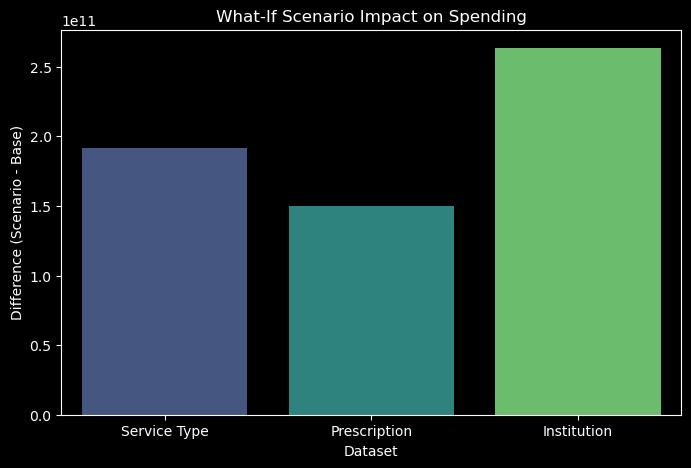

In [46]:
results_df = apply_scenario(
    service_df, prescription_df, institution_df,
    service_model, prescription_model, institution_model,
    visit_change=10,    # %10 müracaat artışı
    cost_change=5,      # %5 maliyet artışı
    disease_rate_change=0
)

print(results_df)

# ==============================================
# 5. Görselleştirme
# ==============================================
plt.figure(figsize=(8,5))
sns.barplot(
    data=results_df,
    x="Dataset",
    y="Difference",
    hue="Dataset",        # 🔹 eklendi
    dodge=False,
    legend=False,
    palette="viridis" )
plt.title("What-If Scenario Impact on Spending")
plt.ylabel("Difference (Scenario - Base)")
plt.show()

In [47]:
!pip install gradio

In [48]:
import matplotlib.pyplot as plt
import gradio as gr

scenarios = {
    "Baseline (No Change)": {"visit_change": 0, "cost_change": 0, "disease_rate_change": 0},
    "Optimistic": {"visit_change": -5, "cost_change": -10, "disease_rate_change": -2},
    "Crisis": {"visit_change": 15, "cost_change": 20, "disease_rate_change": 5}
}

def run_scenario(visit_change, cost_change, disease_rate_change):
    results_df = apply_scenario(
        service_df, prescription_df, institution_df,
        service_model, prescription_model, institution_model,
        visit_change=visit_change,
        cost_change=cost_change,
        disease_rate_change=disease_rate_change
    )

    def format_trillion(x):
        return f"{x/1e12:.2f} Trilyon TL"

    results_df_display = results_df.copy()
    for col in ["Base", "Scenario", "Difference"]:
        results_df_display[col] = results_df_display[col].apply(format_trillion)
    results_df_display["Change (%)"] = results_df["Change (%)"].apply(lambda x: f"{x:.2f}%")

    # ---- Barplot (Difference) ----
    fig_bar, ax = plt.subplots(figsize=(7,5))
    ax.bar(results_df["Dataset"], results_df["Difference"], color="teal")
    ax.set_title("What-If Scenario Impact on Spending")
    ax.set_ylabel("Difference (TL)")
    plt.xticks(rotation=45)
    plt.tight_layout()

    # ---- Pie Chart (Scenario distribution) ----
    fig_pie, ax2 = plt.subplots(figsize=(6,6))
    ax2.pie(results_df["Scenario"], labels=results_df["Dataset"], autopct='%1.1f%%', startangle=90)
    ax2.set_title("Scenario Spending Distribution")

    # ---- Trend Line (Base vs Scenario) ----
    fig_line, ax3 = plt.subplots(figsize=(7,5))
    ax3.plot(results_df["Dataset"], results_df["Base"], marker="o", label="Base")
    ax3.plot(results_df["Dataset"], results_df["Scenario"], marker="o", label="Scenario")
    ax3.set_title("Base vs Scenario Comparison")
    ax3.set_ylabel("Total Spending (TL)")
    ax3.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()

    # ---- Summary ----
    summary = (
        f"{visit_change}% müracaat değişimi, {cost_change}% maliyet değişimi "
        f"ve {disease_rate_change}% hastalık oranı değişimi sonucunda "
        f"toplam harcamalar {results_df['Difference'].sum()/1e9:.2f} Milyar TL "
        f"({results_df['Change (%)'].mean():.2f}%) değişmiştir."
    )

    return results_df_display, fig_bar, fig_pie, fig_line, summary


# ---- Gradio Arayüzü ----
with gr.Blocks() as demo:
    with gr.Row():
        visit_slider = gr.Slider(-20, 20, value=0, step=1, label="Visit Change (%)")
        cost_slider = gr.Slider(-20, 20, value=0, step=1, label="Cost Change (%)")
        disease_slider = gr.Slider(-20, 20, value=0, step=1, label="Disease Rate Change (%)")
    scenario_dropdown = gr.Dropdown(["Custom", "Baseline (No Change)", "Optimistic", "Crisis"], value="Custom", label="Scenario Template")

    outputs = [
        gr.Dataframe(),
        gr.Plot(label="Barplot (Difference)"),
        gr.Plot(label="Pie Chart (Scenario Distribution)"),
        gr.Plot(label="Line Chart (Base vs Scenario)"),
        gr.Textbox(label="Summary")
    ]

    # ---- Scenario seçildiğinde sliderları güncelle ----
    def update_sliders(scenario_name):
        if scenario_name in scenarios:
            s = scenarios[scenario_name]
            return s["visit_change"], s["cost_change"], s["disease_rate_change"]
        else:
            return gr.update(), gr.update(), gr.update()


    scenario_dropdown.change(update_sliders, inputs=scenario_dropdown, outputs=[visit_slider, cost_slider, disease_slider])
    run_button = gr.Button("Run Scenario")
    run_button.click(run_scenario, inputs=[visit_slider, cost_slider, disease_slider], outputs=outputs)

demo.launch()

Running on local URL:  http://127.0.0.1:7862

To create a public link, set `share=True` in `launch()`.
